Quick note: Qiskit is only used for visualization of circuits. The computation are entirely done with SymPy.

In [26]:
import numpy as np
from qiskit.circuit.library import HGate, UnitaryGate
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Operator
tau_num = 2/(1+np.sqrt(5))
om_num = np.exp(np.pi*1j/5)
F_gate = UnitaryGate(np.array([[tau_num,np.sqrt(tau_num)],[np.sqrt(tau_num),-tau_num]]), label='F')
Finv_gate = UnitaryGate(F_gate.inverse(), label='Finv')
B2_gate = UnitaryGate(np.array([[om_num**4*tau_num,om_num**(-3)*np.sqrt(tau_num)],[om_num**(-3)*np.sqrt(tau_num),-tau_num]]), label='B2')
Z12_gate = UnitaryGate(np.array([[1,0],[0,-1]]), label='Z12')
cZ12_gate = Z12_gate.control(1)

In [27]:
import sympy as sp
from sympy.physics.quantum import TensorProduct
from IPython.display import display, Latex
a = sp.symbols('a')
b = sp.symbols('b')
tau = 1/sp.GoldenRatio
F = sp.Matrix([[tau,sp.sqrt(tau)],[sp.sqrt(tau),-tau]])
H = sp.Matrix([[1,1],[1,-1]])/sp.sqrt(2)
Finv = F.inv()
cZ12 = sp.Matrix([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,-1]])
cZ12_rev = sp.Matrix([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,-1]])
om = sp.exp(sp.pi*1j/5)
B2 = sp.Matrix([[om**4*tau,om**(-3)*sp.sqrt(tau)],[om**(-3)*sp.sqrt(tau),-tau]])
I = sp.eye(2)

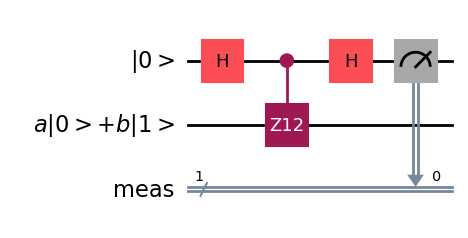

Probability of measuring the first qubit as 0 is:


Abs(a)**2

Probability of measuring the first qubit as 1 is:


Abs(b)**2

In [28]:

qreg1 = QuantumRegister(1, '|0>')
qreg2 = QuantumRegister(1, 'a|0>+b|1>')
creg = ClassicalRegister(1, 'meas')
qc = QuantumCircuit(qreg1, qreg2, creg)

qc.h(qreg1[0])
qc.append(cZ12_gate,[qreg1[0],qreg2[0]])
qc.h(qreg1[0])
qc.measure(qreg1[0],creg[0])

state = sp.Matrix([a,b,0,0])

L1 = TensorProduct(H,I)
L2 = cZ12
L3 = TensorProduct(H,I)
res = sp.simplify(L3*L2*L1*state)
prob0 = sp.Abs(res[0])**2+sp.Abs(res[1])**2
prob1 = sp.Abs(res[2])**2+sp.Abs(res[3])**2
display(qc.draw('mpl'))
# display(Latex(f'$a|00{{\\rangle}}+b|01{{\\rangle}}{{\\mapsto}} {res[0]}|00{{\\rangle}}+{res[1]}|01{{\\rangle}}+{res[2]}|10{{\\rangle}}+{res[3]}|11{{\\rangle}}$'))
print(f'Probability of measuring the first qubit as 0 is:')
display(prob0)
print(f'Probability of measuring the first qubit as 1 is:')
display(prob1)

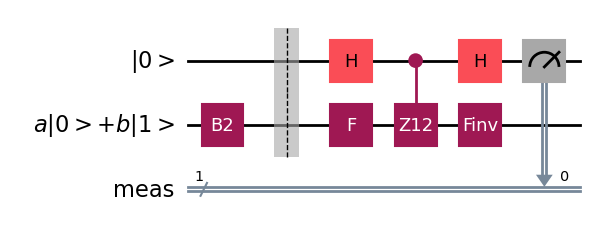

Probability of measuring the first qubit as 0 is:


Abs((-1)**(2/5)*a*(1 + GoldenRatio + (-1)**(3/5)*GoldenRatio*(1 + GoldenRatio)) - sqrt(GoldenRatio)*b*(1 + GoldenRatio - (-1)**(3/5)*(1 + GoldenRatio)))**2/(GoldenRatio*(1 + GoldenRatio)**4) + Abs((-1)**(2/5)*GoldenRatio*a*(1 + GoldenRatio + (-1)**(3/5)*GoldenRatio*(1 + GoldenRatio)) - GoldenRatio**(3/2)*b*(1 + GoldenRatio - (-1)**(3/5)*(1 + GoldenRatio)))**2/(GoldenRatio**4*(1 + GoldenRatio)**4)

Probability of measuring the first qubit as 1 is:


Abs((-1)**(2/5)*sqrt(GoldenRatio)*a*(1 + GoldenRatio - (-1)**(3/5)*(1 + GoldenRatio)) - b*(1 + GoldenRatio)*(GoldenRatio + (-1)**(3/5)))**2/(GoldenRatio*(1 + GoldenRatio)**4) + Abs((-1)**(4/5)*GoldenRatio**(3/2)*a + (-1)**(2/5)*GoldenRatio**(3/2)*a + GoldenRatio*b - (-1)**(2/5)*GoldenRatio**2*b)**2/(GoldenRatio**4*(1 + GoldenRatio)**2)

In [29]:
qreg1 = QuantumRegister(1, '|0>')
qreg2 = QuantumRegister(1, 'a|0>+b|1>')
creg = ClassicalRegister(1, 'meas')
qc = QuantumCircuit(qreg1, qreg2, creg)

qc.append(B2_gate, [qreg2[0]])
qc.barrier()
qc.append(F_gate,[qreg2[0]])
qc.h(qreg1[0])
qc.append(cZ12_gate,[qreg1[0],qreg2[0]])
qc.h(qreg1[0])
qc.append(Finv_gate,[qreg2[0]])
qc.measure(qreg1[0],creg[0])

state = sp.Matrix([a,b,0,0])

L1 = TensorProduct(I,B2)
L2 = TensorProduct(H,F)
L3 = cZ12
L4 = TensorProduct(H,Finv)
res = sp.simplify(L4*L3*L2*L1*state, rational=True)
prob0 = sp.Abs(res[0])**2+sp.Abs(res[1])**2
prob1 = sp.Abs(res[2])**2+sp.Abs(res[3])**2
display(qc.draw('mpl'))

print(f'Probability of measuring the first qubit as 0 is:')
display(prob0)
print(f'Probability of measuring the first qubit as 1 is:')
display(prob1)

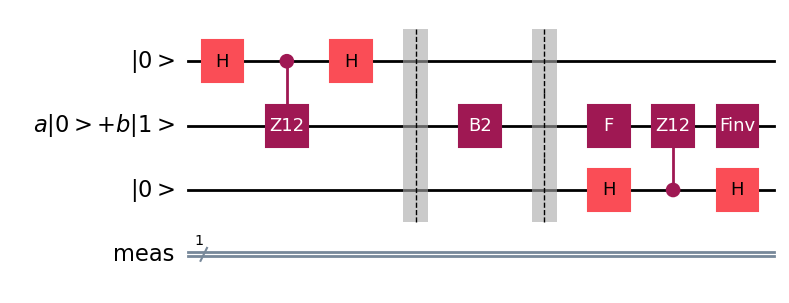

Probability of measuring the first qubit as 0 is:


(8*GoldenRatio + 8*GoldenRatio**2 - 2*sqrt(2)*GoldenRatio**2*I*sqrt(sqrt(5) + 5) - (-1)**(3/5)*sqrt(5)*GoldenRatio**3 - (-1)**(9/10)*sqrt(2)*GoldenRatio**2*sqrt(sqrt(5) + 5) - (-1)**(9/10)*sqrt(2)*GoldenRatio*sqrt(sqrt(5) + 5) - (-1)**(2/5)*GoldenRatio - (-1)**(9/10)*sqrt(2)*sqrt(sqrt(5) + 5) - (-1)**(2/5) + (-1)**(2/5)*sqrt(5) + (-1)**(2/5)*sqrt(5)*GoldenRatio + (-1)**(3/5)*GoldenRatio**3 + (-1)**(1/10)*sqrt(2)*GoldenRatio**3*sqrt(sqrt(5) + 5) + (-1)**(2/5)*sqrt(5)*GoldenRatio**2 + 3*(-1)**(2/5)*GoldenRatio**2 + 4*(-1)**(3/5)*GoldenRatio**2)*Abs(a)**2/(4*GoldenRatio**2*(1 + GoldenRatio**2 + 2*GoldenRatio))

Probability of measuring the first qubit as 1 is:


(4 - (-1)**(9/10)*sqrt(2)*GoldenRatio*sqrt(sqrt(5) + 5) - (-1)**(2/5)*GoldenRatio + (-1)**(2/5)*sqrt(5)*GoldenRatio)*Abs(b)**2/(4*GoldenRatio**2)

Probability of measuring the third qubit as 0 is:


(-sqrt(5)*GoldenRatio**2*Abs(a)**2 - sqrt(5)*GoldenRatio*Abs(a)**2 + 5*GoldenRatio*Abs(a)**2 + 5*GoldenRatio**2*Abs(a)**2 - sqrt(2)*GoldenRatio**2*I*sqrt(sqrt(5) + 5)*Abs(a)**2 - (-1)**(3/5)*sqrt(5)*GoldenRatio**3*Abs(a)**2 - 4*(-1)**(2/5)*GoldenRatio*Abs(a)**2 - (-1)**(9/10)*sqrt(2)*sqrt(sqrt(5) + 5)*Abs(a)**2 - (-1)**(2/5)*Abs(a)**2 + (-1)**(2/5)*sqrt(5)*Abs(a)**2 + (-1)**(3/5)*GoldenRatio**3*Abs(a)**2 + (-1)**(1/10)*sqrt(2)*GoldenRatio**3*sqrt(sqrt(5) + 5)*Abs(a)**2 + sqrt(2)*GoldenRatio*I*sqrt(sqrt(5) + 5)*Abs(a)**2 + 4*(-1)**(3/5)*GoldenRatio**2*Abs(a)**2 + sqrt(5)*GoldenRatio*Abs(b)**2 + 3*GoldenRatio*Abs(b)**2 + sqrt(5)*GoldenRatio**2*Abs(b)**2 + 3*GoldenRatio**2*Abs(b)**2 - sqrt(2)*GoldenRatio**2*I*sqrt(sqrt(5) + 5)*Abs(b)**2 - sqrt(2)*GoldenRatio*I*sqrt(sqrt(5) + 5)*Abs(b)**2 - (-1)**(9/10)*sqrt(2)*GoldenRatio**2*sqrt(sqrt(5) + 5)*Abs(b)**2 - (-1)**(9/10)*sqrt(2)*GoldenRatio*sqrt(sqrt(5) + 5)*Abs(b)**2 + (-1)**(2/5)*sqrt(5)*GoldenRatio*Abs(b)**2 + 3*(-1)**(2/5)*GoldenRatio*Abs

Probability of measuring the third qubit as 1 is:


(sqrt(5)*GoldenRatio*Abs(a)**2 + 3*GoldenRatio*Abs(a)**2 - sqrt(2)*GoldenRatio*I*sqrt(sqrt(5) + 5)*Abs(a)**2 - (-1)**(9/10)*sqrt(2)*GoldenRatio*sqrt(sqrt(5) + 5)*Abs(a)**2 + (-1)**(2/5)*sqrt(5)*GoldenRatio*Abs(a)**2 + 3*(-1)**(2/5)*GoldenRatio*Abs(a)**2 - sqrt(5)*GoldenRatio*Abs(b)**2 + GoldenRatio*Abs(b)**2 + 4*Abs(b)**2 - 4*(-1)**(2/5)*GoldenRatio*Abs(b)**2 - (-1)**(9/10)*sqrt(2)*GoldenRatio**2*sqrt(sqrt(5) + 5)*Abs(b)**2 - (-1)**(2/5)*GoldenRatio**2*Abs(b)**2 + (-1)**(2/5)*sqrt(5)*GoldenRatio**2*Abs(b)**2 + sqrt(2)*GoldenRatio*I*sqrt(sqrt(5) + 5)*Abs(b)**2)/(4*GoldenRatio**2*(1 + GoldenRatio))

In [30]:

qreg1 = QuantumRegister(1, '|0>')
qreg2 = QuantumRegister(1, 'a|0>+b|1>')
qreg3 = QuantumRegister(1, ' |0>')
creg = ClassicalRegister(1, 'meas')
qc = QuantumCircuit(qreg1, qreg2, qreg3, creg)

qc.h(qreg1[0])
qc.append(cZ12_gate,[qreg1[0],qreg2[0]])
qc.h(qreg1[0])
qc.barrier()
qc.append(B2_gate, [qreg2[0]])
qc.barrier()
qc.append(F_gate,[qreg2[0]])
qc.h(qreg3[0])
qc.append(cZ12_gate,[qreg3[0],qreg2[0]])
qc.h(qreg3[0])
qc.append(Finv_gate,[qreg2[0]])

L1 = TensorProduct(H,I,I)
L2 = TensorProduct(cZ12,I)
L3 = TensorProduct(H,I,I)
L4 = TensorProduct(I,B2,I)
L5 = TensorProduct(I,F,H)
L6 = TensorProduct(I,cZ12_rev)
L7 = TensorProduct(I,Finv,H)
state = sp.Matrix([a,0,b,0,0,0,0,0])
res = sp.simplify(L7*L6*L5*L4*L3*L2*L1*state, rational=True)
first_prob0 = sp.simplify(sp.Abs(res[0])**2+sp.Abs(res[1])**2+sp.Abs(res[2])**2+sp.Abs(res[3])**2)
first_prob1 = sp.simplify(sp.Abs(res[4])**2+sp.Abs(res[5])**2+sp.Abs(res[6])**2+sp.Abs(res[7])**2)
second_prob0 = sp.simplify(sp.Abs(res[0])**2+sp.Abs(res[2])**2+sp.Abs(res[4])**2+sp.Abs(res[6])**2)
second_prob1 = sp.simplify(sp.Abs(res[1])**2+sp.Abs(res[3])**2+sp.Abs(res[5])**2+sp.Abs(res[7])**2)
display(qc.draw('mpl'))

print(f'Probability of measuring the first qubit as 0 is:')
display(first_prob0)
print(f'Probability of measuring the first qubit as 1 is:')
display(first_prob1)
print(f'Probability of measuring the third qubit as 0 is:')
display(second_prob0)
print(f'Probability of measuring the third qubit as 1 is:')
display(second_prob1)